In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import transforms, datasets
from torch.utils.data import DataLoader, random_split
import json
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
import time
import os

In [2]:
# 检查CUDA可用性
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"使用设备: {device}")

使用设备: cuda


In [3]:
# 创建结果目录
os.makedirs('results', exist_ok=True)

In [4]:
# 针对1600x350尺寸的预处理
transform = transforms.Compose([
    transforms.Resize((350, 1600)),  # 保持原始宽高比
    transforms.CenterCrop((320, 1536)),  # 中心裁剪以去除边缘噪点
    transforms.Resize((80, 384)),  # 按比例缩小到1/4
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [5]:
# 加载数据集
dataset = datasets.ImageFolder('D:\STUDY\internship\code_internship\dataset\images', transform=transform)

<>:2: SyntaxWarning: invalid escape sequence '\S'
<>:2: SyntaxWarning: invalid escape sequence '\S'
C:\Users\user\AppData\Local\Temp\ipykernel_15016\707649435.py:2: SyntaxWarning: invalid escape sequence '\S'
  dataset = datasets.ImageFolder('D:\STUDY\internship\code_internship\dataset\images', transform=transform)


In [6]:
# 保存类别映射
with open('results/class_indices.json', 'w') as f:
    json.dump(dataset.class_to_idx, f)

In [7]:
# 划分训练集和验证集
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size
train_dataset, val_dataset = random_split(dataset, [train_size, val_size])
# 创建数据加载器
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True, num_workers=4)
val_loader = DataLoader(val_dataset, batch_size=16, num_workers=4)

In [8]:
# 针对1600x350特殊尺寸的CNN模型
class AspectAwareCNN(nn.Module):
    def __init__(self, num_classes=5):
        super(AspectAwareCNN, self).__init__()
        # 输入尺寸: [3, 80, 384]
        self.conv_layers = nn.Sequential(
            # 第1层卷积
            nn.Conv2d(3, 32, kernel_size=(3, 7), padding=(1, 3)),  # 使用宽核适应宽图像
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d((2, 4)),  # 输出: [32, 40, 96]
            
            # 第2层卷积
            nn.Conv2d(32, 64, kernel_size=(3, 7), padding=(1, 3)),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d((2, 4)),  # 输出: [64, 20, 24]
            
            # 第3层卷积
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d((2, 2)),  # 输出: [128, 10, 12]
        )
        
        # 自适应池化适应不同尺寸
        self.adaptive_pool = nn.AdaptiveAvgPool2d((5, 6))
        
        self.fc_layers = nn.Sequential(
            nn.Linear(128 * 5 * 6, 512),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(512, num_classes)
        )
    
    def forward(self, x):
        x = self.conv_layers(x)
        x = self.adaptive_pool(x)
        x = torch.flatten(x, 1)
        return self.fc_layers(x)

In [9]:
# 初始化模型
model = AspectAwareCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.0005)

In [10]:
# 训练函数
def train(model, loader, optimizer, criterion):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    
    for inputs, labels in loader:
        inputs, labels = inputs.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * inputs.size(0)
        _, predicted = torch.max(outputs, 1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)
    
    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc

# 验证函数
def validate(model, loader, criterion):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0
    
    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            
            running_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs, 1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)
    
    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc

In [11]:
# 记录训练过程的指标
train_losses = []
train_accs = []
val_losses = []
val_accs = []
best_acc = 0.0

In [12]:
# 训练循环
num_epochs = 30
start_time = time.time()

print(f"{'Epoch':^7} | {'Train Loss':^12} | {'Train Acc':^10} | {'Val Loss':^10} | {'Val Acc':^9} | {'Time':^9}")
print("-" * 70)

for epoch in range(num_epochs):
    epoch_start = time.time()
    
    # 训练并验证
    train_loss, train_acc = train(model, train_loader, optimizer, criterion)
    val_loss, val_acc = validate(model, val_loader, criterion)
    
    # 记录指标
    train_losses.append(train_loss)
    train_accs.append(train_acc)
    val_losses.append(val_loss)
    val_accs.append(val_acc)
    
    # 保存最佳模型
    if val_acc > best_acc:
        best_acc = val_acc
        torch.save(model.state_dict(), 'results/best_model.pth')
    
    epoch_time = time.time() - epoch_start
    
    # 打印进度
    print(f"{epoch+1:^7} | {train_loss:^12.4f} | {train_acc:^10.4f} | "
          f"{val_loss:^10.4f} | {val_acc:^9.4f} | {epoch_time:^8.2f}s")

total_time = time.time() - start_time
print(f"\n训练完成! 总耗时: {total_time/60:.2f}分钟")
print(f"最佳验证准确率: {best_acc:.4f}")

 Epoch  |  Train Loss  | Train Acc  |  Val Loss  |  Val Acc  |   Time   
----------------------------------------------------------------------
   1    |    1.1072    |   0.5075   |   0.8845   |  0.5600   |  19.32  s
   2    |    0.6591    |   0.7250   |   0.4730   |  0.7850   |  18.68  s
   3    |    0.5527    |   0.7438   |   0.5543   |  0.7250   |  18.57  s
   4    |    0.5058    |   0.7650   |   0.5145   |  0.7450   |  18.44  s
   5    |    0.4967    |   0.7812   |   0.4212   |  0.8150   |  18.59  s
   6    |    0.4497    |   0.7975   |   0.3410   |  0.8450   |  18.55  s
   7    |    0.4075    |   0.8100   |   0.3216   |  0.8450   |  18.86  s
   8    |    0.4726    |   0.7850   |   0.3224   |  0.8450   |  18.59  s
   9    |    0.4126    |   0.8037   |   0.3613   |  0.7850   |  18.81  s
  10    |    0.3893    |   0.8125   |   0.3079   |  0.8450   |  20.06  s
  11    |    0.3494    |   0.8313   |   0.2978   |  0.8700   |  19.76  s
  12    |    0.3347    |   0.8475   |   0.3172   |  0

d:\Python\Lib\site-packages\IPython\core\events.py:82: UserWarning: Glyph 25439 (\N{CJK UNIFIED IDEOGRAPH-635F}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
d:\Python\Lib\site-packages\IPython\core\events.py:82: UserWarning: Glyph 22833 (\N{CJK UNIFIED IDEOGRAPH-5931}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
d:\Python\Lib\site-packages\IPython\core\events.py:82: UserWarning: Glyph 26354 (\N{CJK UNIFIED IDEOGRAPH-66F2}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
d:\Python\Lib\site-packages\IPython\core\events.py:82: UserWarning: Glyph 32447 (\N{CJK UNIFIED IDEOGRAPH-7EBF}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
d:\Python\Lib\site-packages\IPython\core\events.py:82: UserWarning: Glyph 35757 (\N{CJK UNIFIED IDEOGRAPH-8BAD}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
d:\Python\Lib\site-packages\IPython\core\events.py:82: UserWarning: Glyph 32451 (\N{CJK UNIFIED IDEOGRAPH-7EC3}) missing from font(s) DejaVu Sans

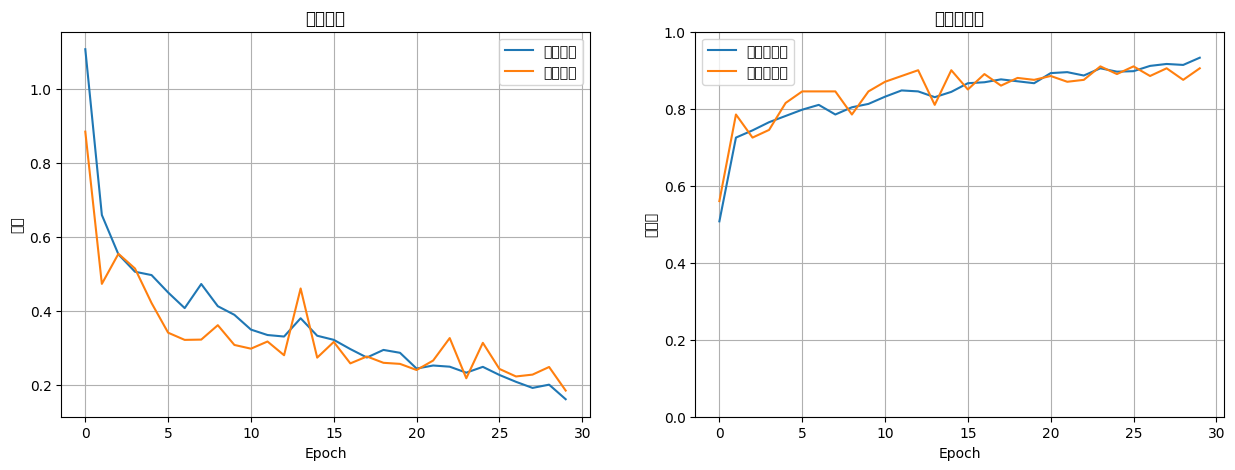

In [13]:
# 绘制训练曲线
plt.figure(figsize=(15, 5))

# 损失曲线
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='训练损失')
plt.plot(val_losses, label='验证损失')
plt.title('损失曲线')
plt.xlabel('Epoch')
plt.ylabel('损失')
plt.legend()
plt.grid(True)

# 准确率曲线
plt.subplot(1, 2, 2)
plt.plot(train_accs, label='训练准确率')
plt.plot(val_accs, label='验证准确率')
plt.title('准确率曲线')
plt.xlabel('Epoch')
plt.ylabel('准确率')
plt.ylim(0, 1)  # 设置y轴范围0-1
plt.legend()
plt.grid(True)

Text(95.72222222222221, 0.5, '真实标签')

d:\Python\Lib\site-packages\IPython\core\events.py:82: UserWarning: Glyph 30495 (\N{CJK UNIFIED IDEOGRAPH-771F}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
d:\Python\Lib\site-packages\IPython\core\events.py:82: UserWarning: Glyph 23454 (\N{CJK UNIFIED IDEOGRAPH-5B9E}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
d:\Python\Lib\site-packages\IPython\core\events.py:82: UserWarning: Glyph 26631 (\N{CJK UNIFIED IDEOGRAPH-6807}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
d:\Python\Lib\site-packages\IPython\core\events.py:82: UserWarning: Glyph 31614 (\N{CJK UNIFIED IDEOGRAPH-7B7E}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
d:\Python\Lib\site-packages\IPython\core\events.py:82: UserWarning: Glyph 28151 (\N{CJK UNIFIED IDEOGRAPH-6DF7}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
d:\Python\Lib\site-packages\IPython\core\events.py:82: UserWarning: Glyph 28102 (\N{CJK UNIFIED IDEOGRAPH-6DC6}) missing from font(s) DejaVu Sans

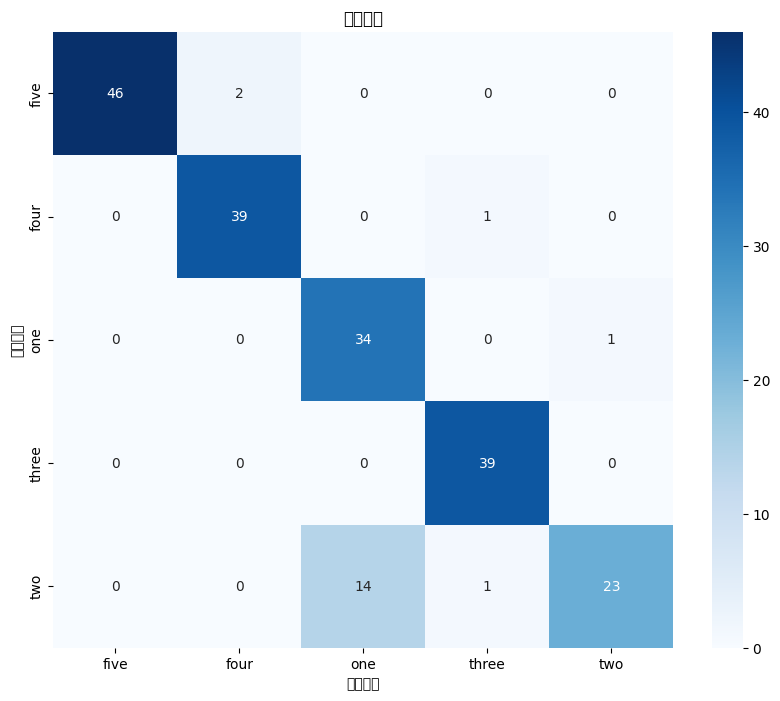

In [14]:
# 绘制混淆矩阵（额外评估）
from sklearn.metrics import confusion_matrix
import seaborn as sns

# 收集所有预测
all_labels = []
all_preds = []

model.eval()
with torch.no_grad():
    for inputs, labels in val_loader:
        inputs = inputs.to(device)
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        
        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())

# 生成混淆矩阵
cm = confusion_matrix(all_labels, all_preds)

# 类别名称
class_names = list(dataset.class_to_idx.keys())

# 绘制混淆矩阵
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, yticklabels=class_names)
plt.title('混淆矩阵')
plt.xlabel('预测标签')
plt.ylabel('真实标签')

In [15]:
# 预测函数示例
def predict_image(image_path):
    # 加载类别映射
    with open('results/class_indices.json') as f:
        class_mapping = json.load(f)
    idx_to_class = {v: k for k, v in class_mapping.items()}
    
    # 加载并预处理图像
    image = Image.open(image_path).convert('RGB')
    image_tensor = transform(image).unsqueeze(0).to(device)
    
    # 预测
    model.load_state_dict(torch.load('results/best_model.pth'))
    model.eval()
    with torch.no_grad():
        output = model(image_tensor)
        probabilities = torch.softmax(output, dim=1)[0] * 100
        _, predicted_idx = torch.max(output, 1)
        predicted_class = idx_to_class[predicted_idx.item()]
    
    # 打印每个类别的概率
    print("\n预测结果:")
    for i, class_name in enumerate(class_names):
        print(f"{class_name}: {probabilities[i]:.2f}%")
    
    return predicted_class

In [17]:
# 测试预测
test_image = r'D:\STUDY\internship\raw_data\100µm_10Hz_5N\Séquence images\im0031.tif'  # 替换为实际路径
print(f"\n测试图像预测结果: {predict_image(test_image)}")


预测结果:
five: 0.00%
four: 0.00%
one: 0.00%
three: 0.00%
two: 99.99%

测试图像预测结果: two


C:\Users\user\AppData\Local\Temp\ipykernel_15016\172492948.py:13: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load('results/best_model.pth'))
